# EDA (`emnist-letters.csv`)

Dataset path used below: `emnist-letters.csv` (placed next to this notebook).

**Expected layout:** no header; **column 0 = class label**, columns **1–784 = flattened 28×28 grayscale pixels** (784 = 28×28).

**EMNIST Letters** normally uses **26 classes (A–Z)**. Published extracts often encode letters as **1–26** (sometimes **0–25** — we check both below).

From a quick preview of your file, **labels can be negative** (e.g. `-2`) and some rows look like **flat filler images** — those are **data errors** to filter or fix before training.

In [2]:
# Restricts GPU usage
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

In [3]:
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Load data
data = pd.read_csv("emnist-letters.csv")

In [5]:
# Separate labels and pixel data using pandas iloc
labels = data.iloc[:, 0].values
pixels = data.iloc[:, 1:].values

# Identify unique labels and counts
unique_labels, counts = np.unique(labels, return_counts=True)
print(f"Unique Labels: {unique_labels}")
print(f"Number of samples: {len(labels)}")

Unique Labels: [-2 -1  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26]
Number of samples: 99039


In [6]:
print(f"Number of values in pixel[1]: {pixels[1].size}")
print(pixels[1])

Number of values in pixel[1]: 784
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   4  21  50 125 114  39
  37  32   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   3  77 140 203 233 250 254 253 250 250 243 127  10   0   0   0   0
   0   0   0   0   0   0   0   0   0   0  20 170 241 204 140 127 127 127
 127 141 220 254 253 208 115   8   0   0   0   0   0   0   0   0   0   0
   0   1  95 248 195  36   9   4   4   4   4  11  79 208 253 254 243  96
  34   1   0   0   0   0   0   0   0   0   1  47 243 195  12   0   0   0
   0   0   0   0 

Issues spotted:


Extra labels -1 and -2 (Not in alphabets)

Data is already flattened (784 pixels = 28*28) so we reshape back to image



-----------------
Visualising


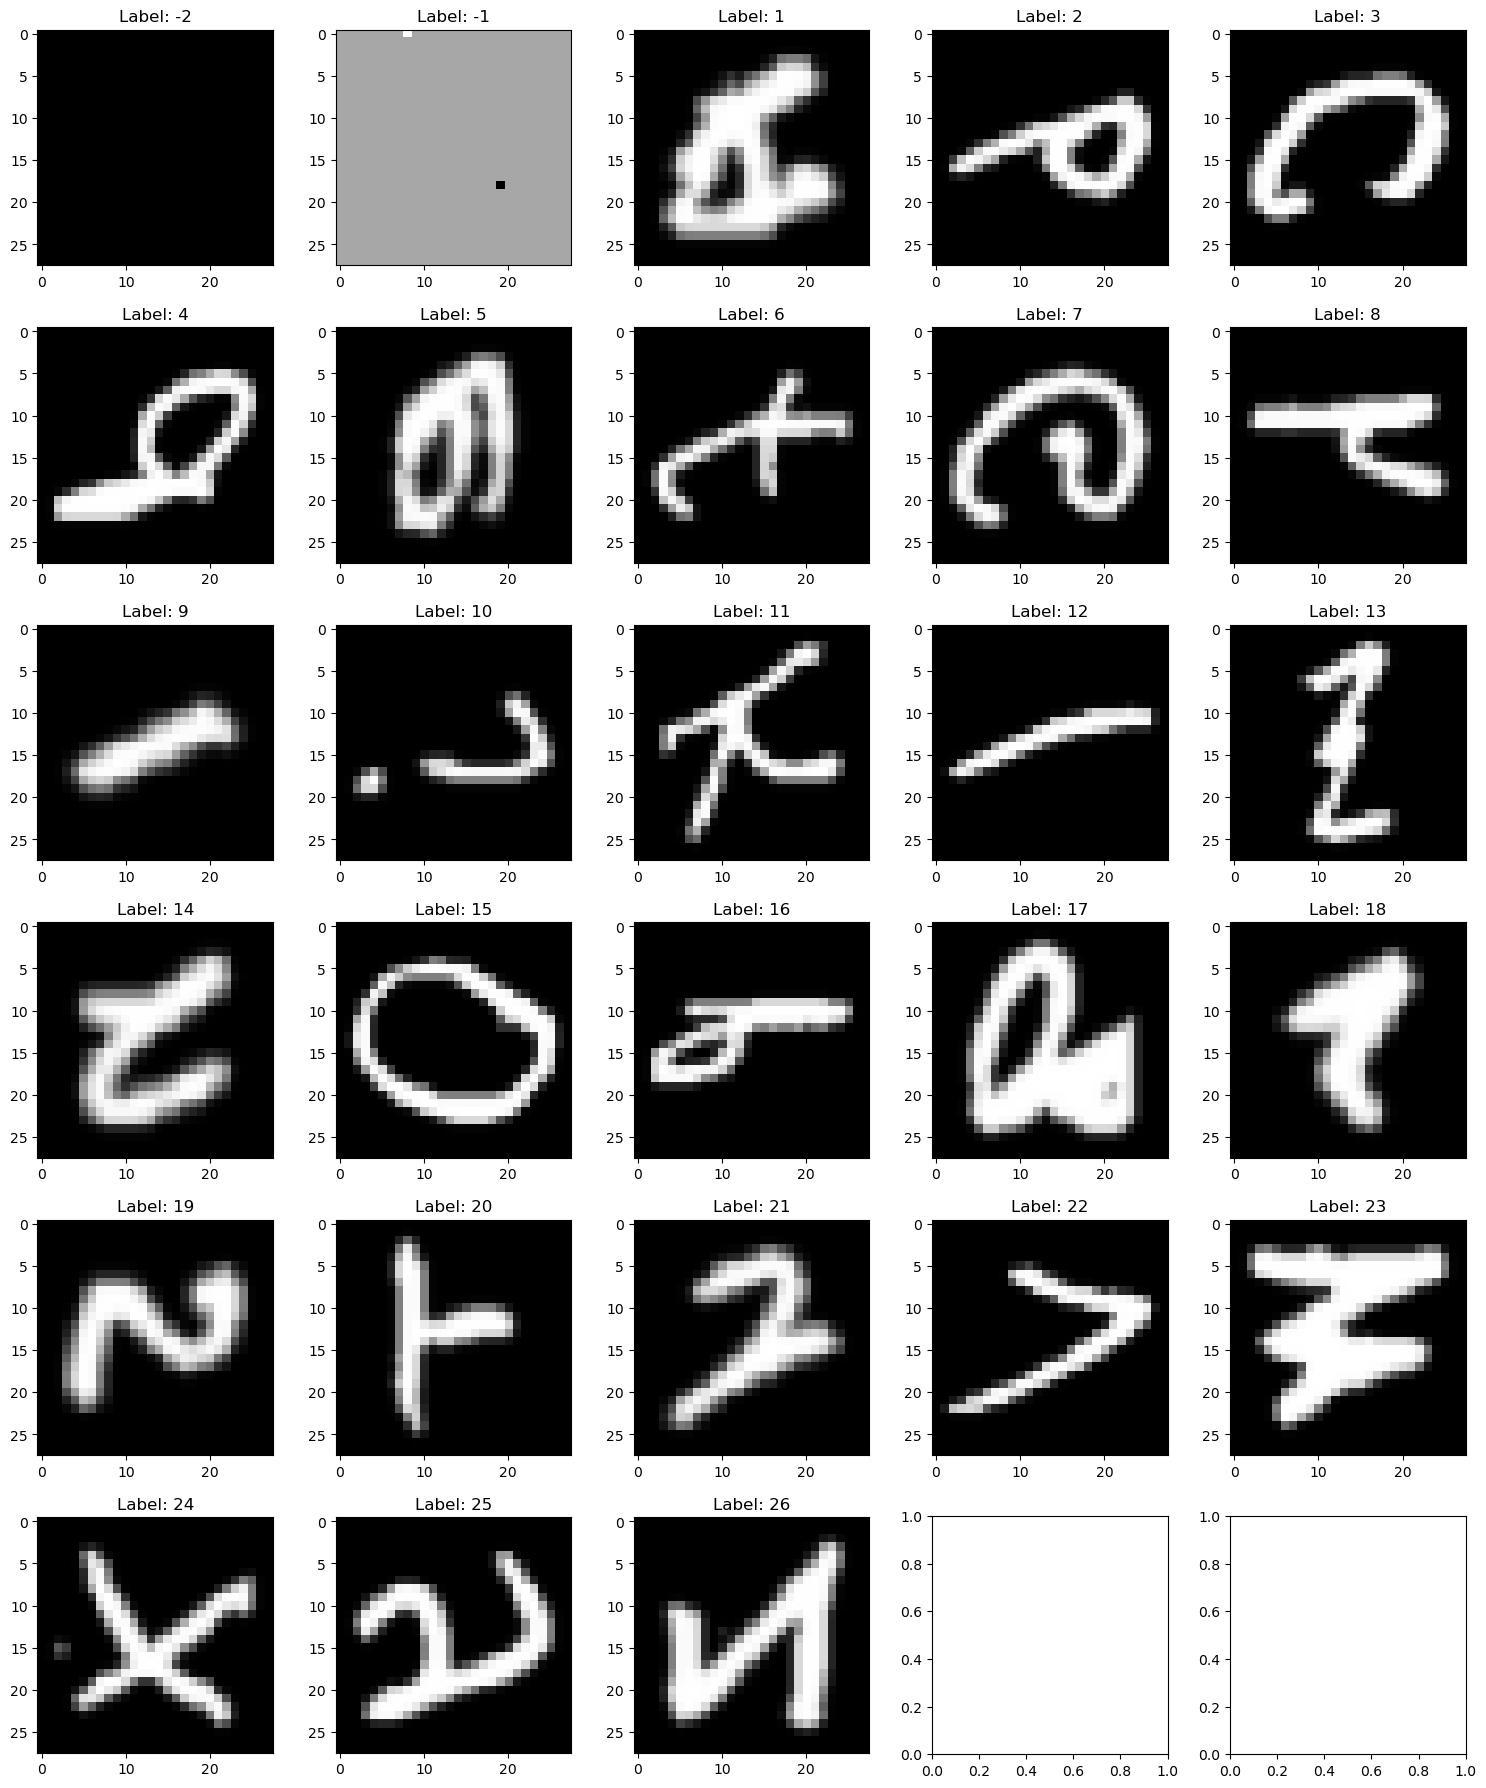

In [7]:
unique_labels = sorted(data.iloc[:, 0].unique())
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
axes = axes.flatten()

for i, label in enumerate(unique_labels):
    img = data[data.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {label}")


plt.tight_layout()
plt.show()

Issues:



1) The orientation of the letters are disoriented.
  
   - Solution: need to flip across x axis first, then rotate it 90 degrees clockwise

2) Label -2 and -1 seem to be plain data





In [8]:
import numpy as np

# Loop through and fix orientation in-place
for i in range(len(pixels)):
    # Reshape to 28x28
    img = pixels[i].reshape(28, 28)

    # Fix orientation
    img_flipped = np.flip(img, axis=-1)
    img_fixed = np.rot90(img_flipped)

    # Flatten back into the same array
    pixels[i] = img_fixed.flatten()

# Sync back to the main dataframe
data.iloc[:, 1:] = pixels



test if orientation is fixed

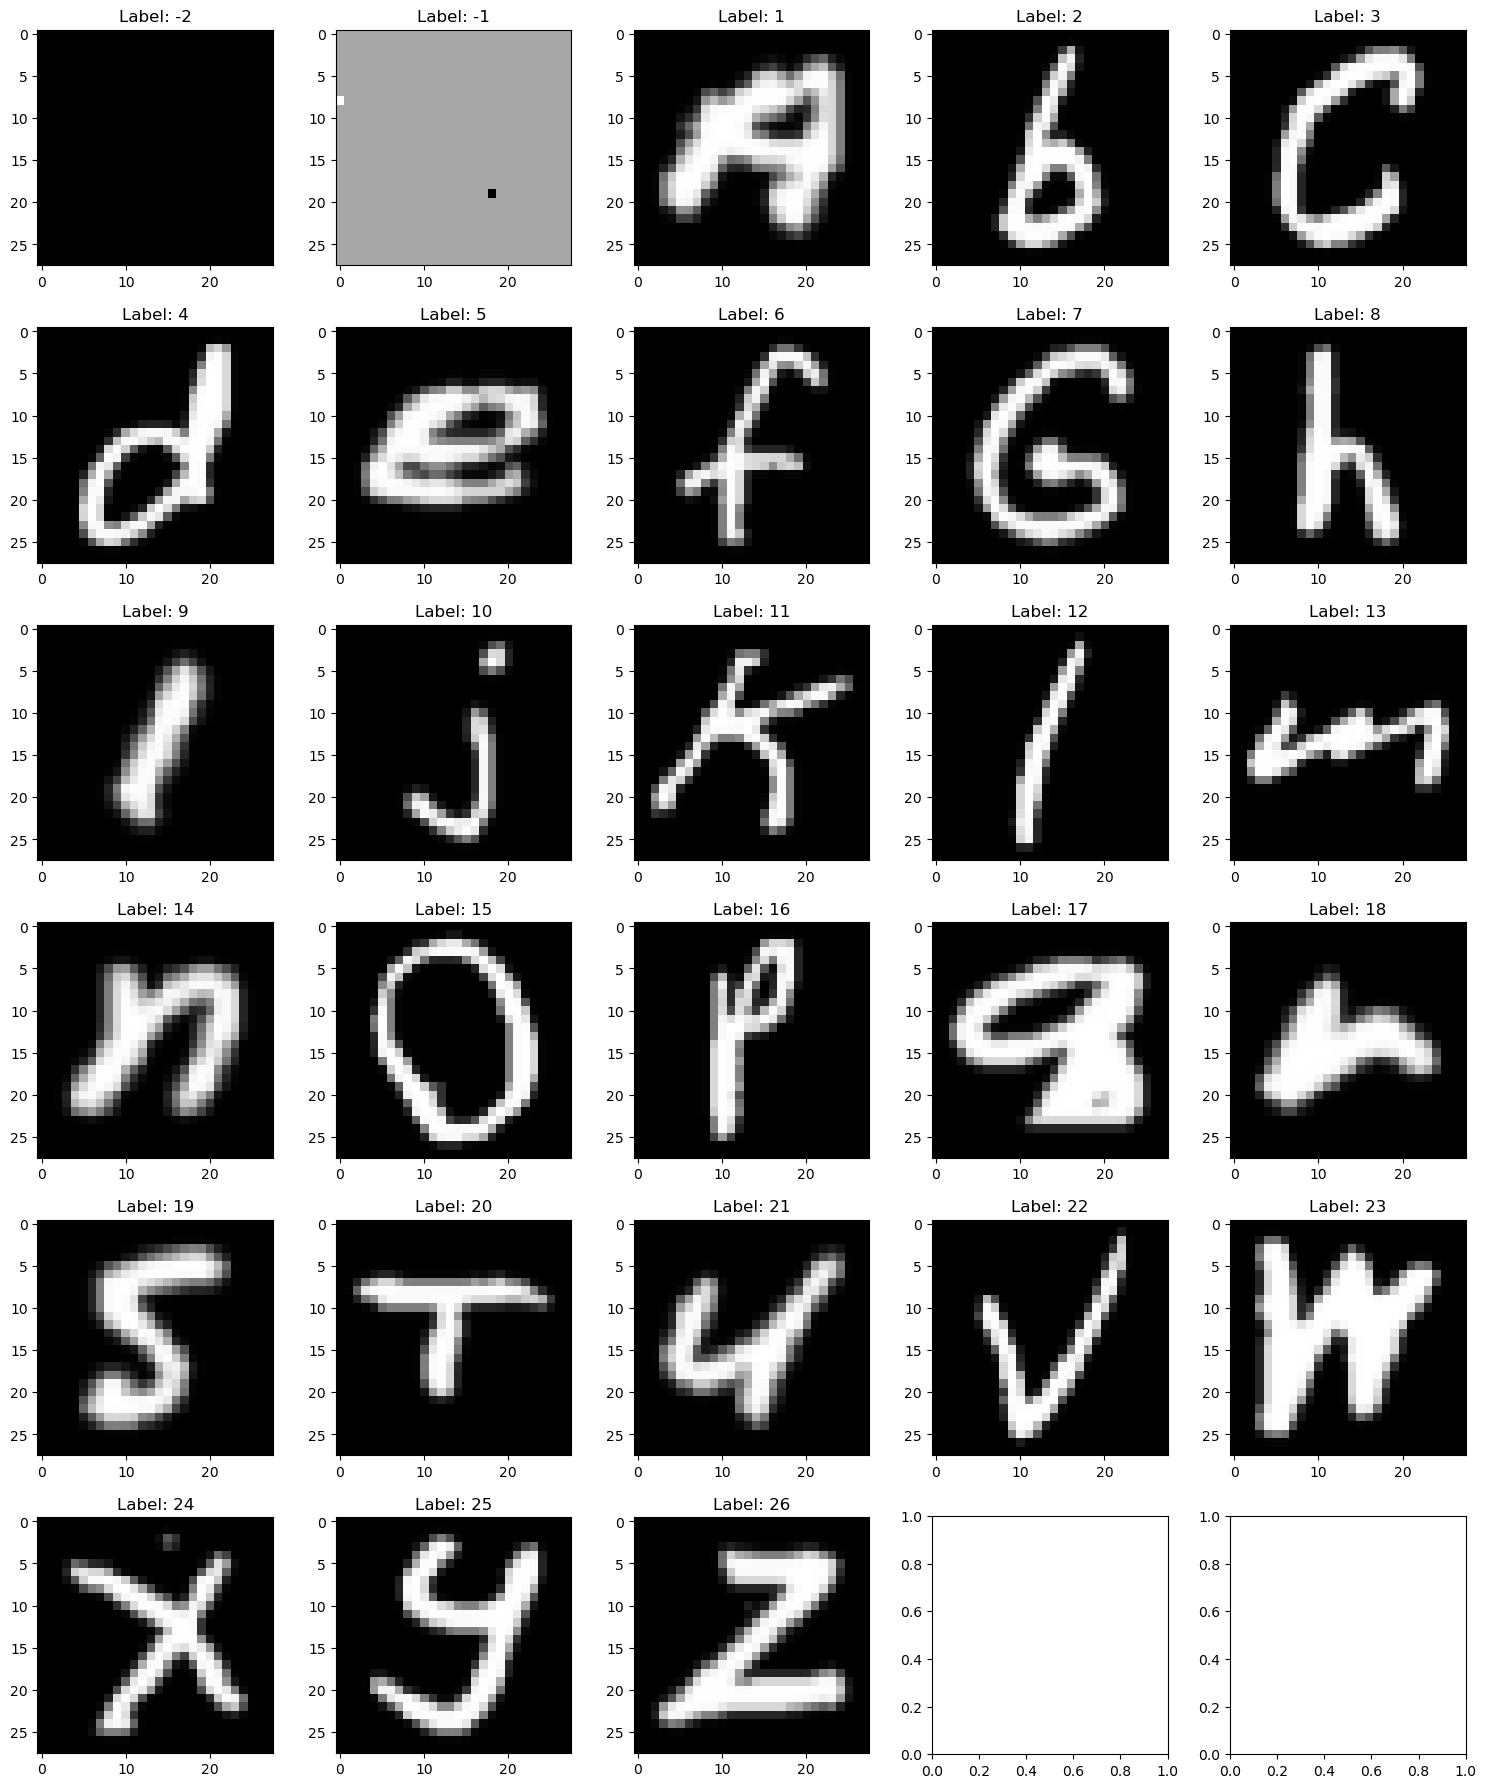

In [9]:
unique_labels = sorted(data.iloc[:, 0].unique())
fig, axes = plt.subplots(6, 5, figsize=(15, 18))
axes = axes.flatten()

for i, label in enumerate(unique_labels):
    img = data[data.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(f"Label: {label}")


plt.tight_layout()
plt.show()

In [10]:
print(f"Total samples remaining: {len(data)}")

Total samples remaining: 99039


Label -1 and -2 Look like unnecessary data. We can drop these 2 labels.

In [11]:
data = data[np.isin(labels, [-1, -2]) == False]
labels = data.iloc[:, 0].values
pixels = data.iloc[:, 1:].values


print(f"Remaining Unique Labels: {np.unique(labels)}")
print(f"Total samples remaining: {len(data)}")

Remaining Unique Labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26]
Total samples remaining: 88799


In [ ]:
# Class distribution bar chart
unique_labels, counts = np.unique(labels, return_counts=True)
label_names = [chr(i + 64) for i in unique_labels]  # 1=A, 2=B ... 26=Z

plt.figure(figsize=(14, 5))
plt.bar(label_names, counts, color='steelblue')
plt.title('Class Distribution — Samples per Letter')
plt.xlabel('Letter')
plt.ylabel('Number of Samples')
plt.tight_layout()
plt.show()

print(f"Min samples in a class: {counts.min()}")
print(f"Max samples in a class: {counts.max()}")

Check Every Set of each alphabet

EDA FINISHED

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.utils import to_categorical

In [13]:
from sklearn.model_selection import train_test_split

# Splitting the data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    pixels,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 71039
Testing samples: 17760


In [14]:
# fix random seed for reproducibility
seed = 1
np.random.seed(seed)

In [15]:
# reshape to be [samples][height][width][channel]
# default in TF is N H W C
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1).astype('float32')
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1).astype('float32')
# normalize inputs from 0-255 to 0-1
X_train = X_train / 255
X_test = X_test / 255
# one hot encode outputs
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
num_classes = y_test.shape[1]
# build the model
# create model
model = Sequential()
model.add(Conv2D(32, (5, 5), input_shape=(28, 28, 1), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
# Compile model
model.compile(loss='categorical_crossentropy',
 optimizer='adam', metrics=['accuracy'])
# Fit the model
history = model.fit(X_train, y_train, validation_data=(X_test, y_test),
 epochs=10, batch_size=200, verbose=1)
# Final evaluation of the model
scores = model.evaluate(X_test, y_test, verbose=0)
print("CNN Error: %.2f%%" % (100-scores[1]*100))

Epoch 1/10
356/356 [==============================] - 12s 7ms/step - loss: 0.8269 - accuracy: 0.7550 - val_loss: 0.4306 - val_accuracy: 0.8685
Epoch 2/10
356/356 [==============================] - 2s 5ms/step - loss: 0.3834 - accuracy: 0.8785 - val_loss: 0.3442 - val_accuracy: 0.8907
Epoch 3/10
356/356 [==============================] - 2s 4ms/step - loss: 0.3067 - accuracy: 0.9000 - val_loss: 0.3089 - val_accuracy: 0.9024
Epoch 4/10
356/356 [==============================] - 2s 5ms/step - loss: 0.2663 - accuracy: 0.9128 - val_loss: 0.2800 - val_accuracy: 0.9116
Epoch 5/10
356/356 [==============================] - 2s 5ms/step - loss: 0.2359 - accuracy: 0.9208 - val_loss: 0.2701 - val_accuracy: 0.9124
Epoch 6/10
356/356 [==============================] - 2s 5ms/step - loss: 0.2108 - accuracy: 0.9287 - val_loss: 0.2691 - val_accuracy: 0.9118
Epoch 7/10
356/356 [==============================] - 2s 5ms/step - loss: 0.1915 - accuracy: 0.9349 - val_loss: 0.2513 - val_accuracy: 0.9217
Epoch

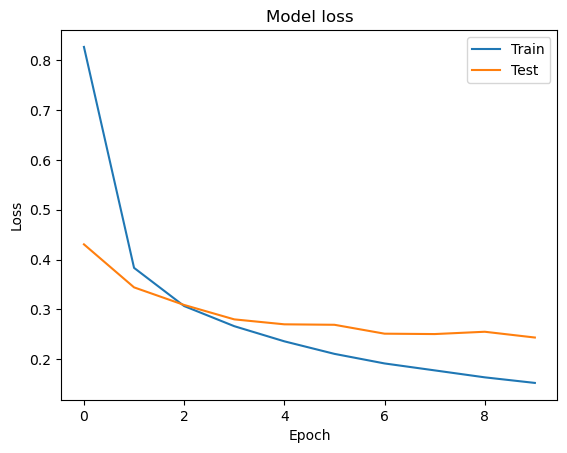

In [16]:
def plot_loss(loss,val_loss):
  plt.figure()
  plt.plot(loss)
  plt.plot(val_loss)
  plt.title('Model loss')
  plt.ylabel('Loss')
  plt.xlabel('Epoch')
  plt.legend(['Train', 'Test'], loc='upper right')
  plt.show()


plot_loss(history.history['loss'], history.history['val_loss'])

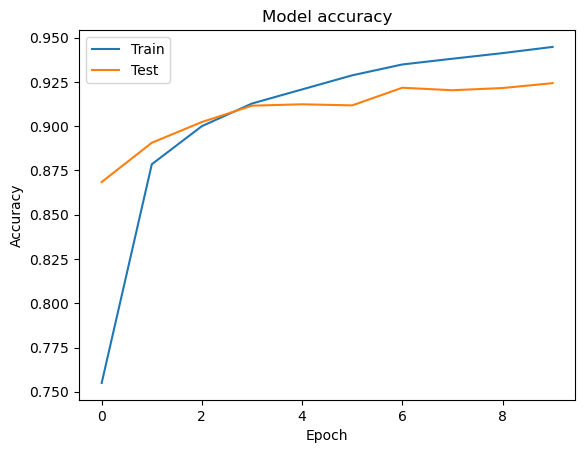

In [17]:
def plot_accuracy(acc,val_acc):
  # Plot training & validation accuracy values
  plt.figure()
  plt.plot(acc)
  plt.plot(val_acc)
  plt.title('Model accuracy')
  plt.ylabel('Accuracy')
  plt.xlabel('Epoch')
  plt.legend(['Train', 'Test'], loc='upper left')
  plt.show()

plot_accuracy(history.history['accuracy'], history.history['val_accuracy'])

MODEL ACCURACY INCREASES UPTO 3 IN BOTH SETS

ACCURACY FLATTENS FOR TEST SET, TRAINING KEEPS IMPROVING. We are overfitting.

In [18]:
# for size in training_sizes:
#   	# Get a fraction of training data (we only care about the training data)
#     X_train_frac, y_train_frac = X_train[:size], y_train[:size]

#     # Reset the model to the initial weights and train it on the new training data fraction
#     model.set_weights(initial_weights)
#     model.fit(X_train_frac, y_train_frac, epochs = 50, callbacks = [early_stop])

#     # Evaluate and store both: the training data fraction and the complete test set results
#     train_accs.append(model.evaluate(X_train, y_train)[1])
#     test_accs.append(model.evaluate(X_test, y_test)[1])
    
# # Plot train vs test accuracies
# plot_results(train_accs, test_accs)

NameError: name 'training_sizes' is not defined

555/555 [==============================] - 1s 2ms/step


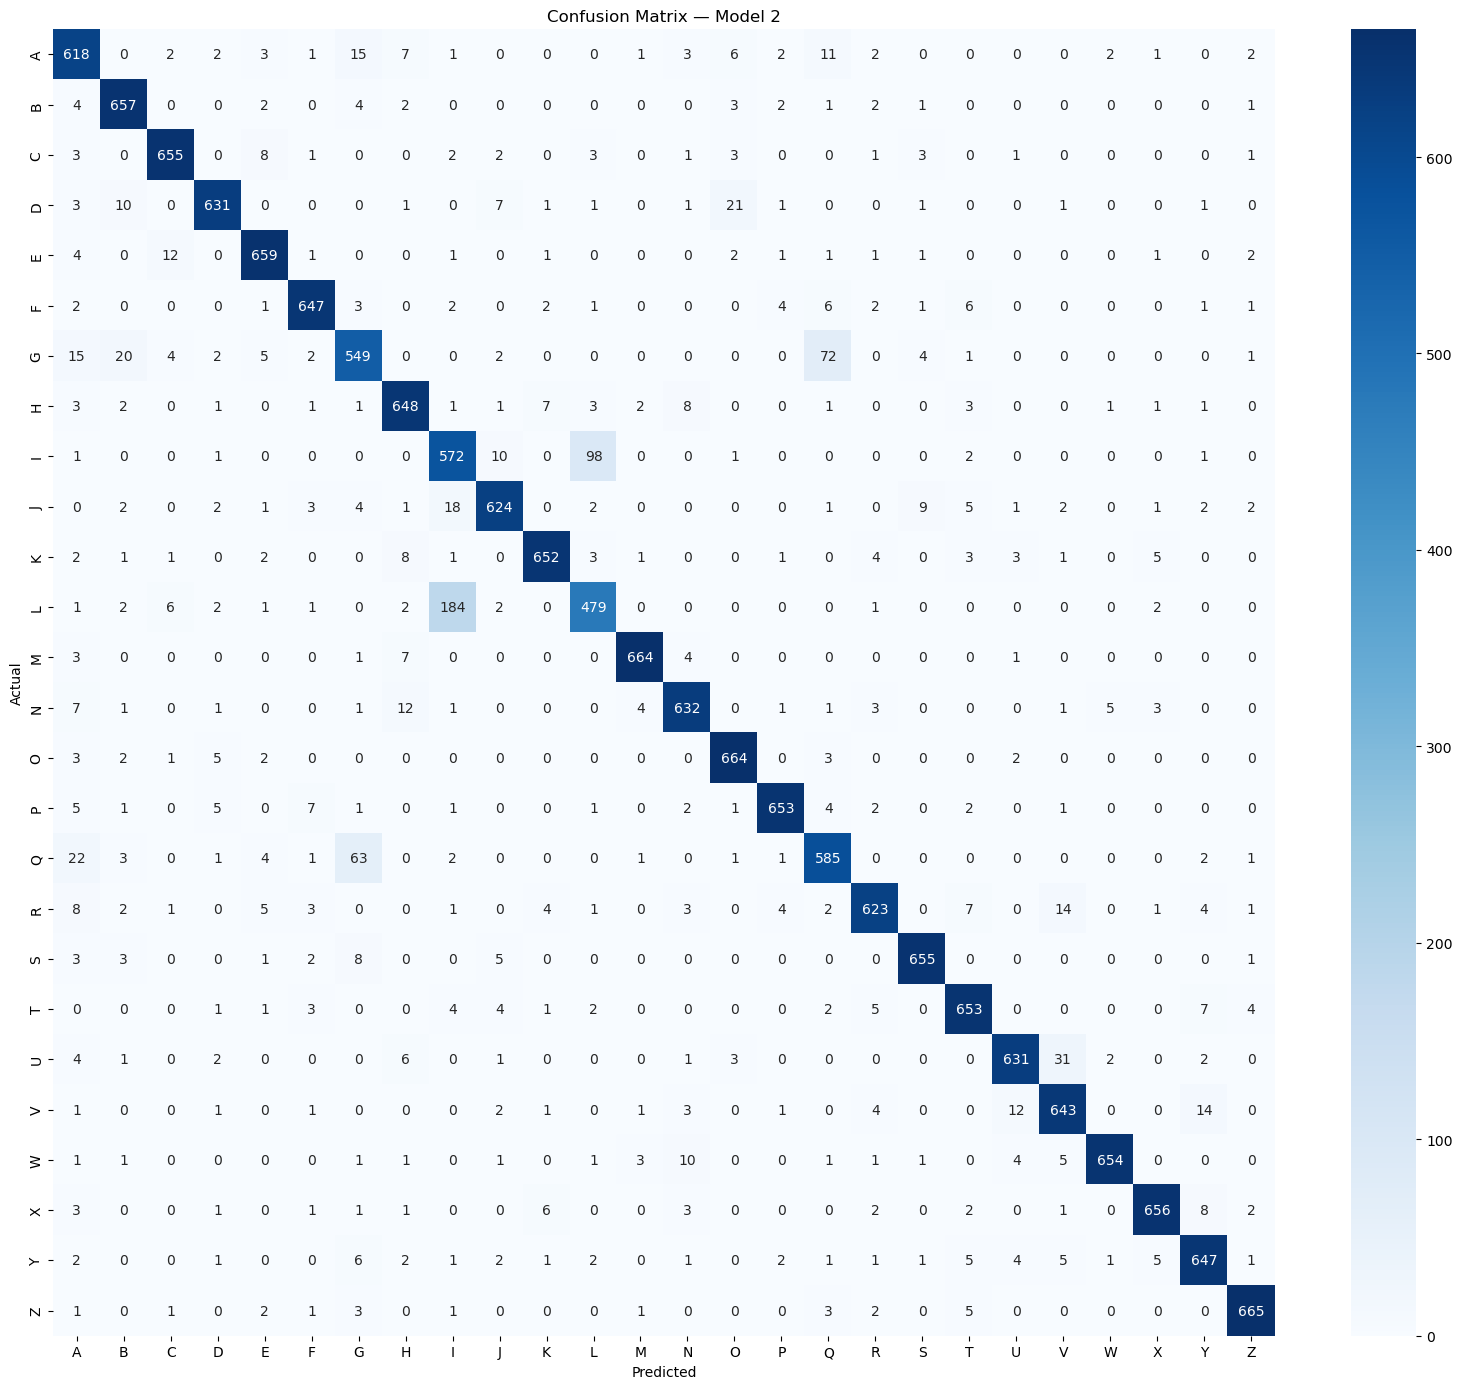

              precision    recall  f1-score   support

           A       0.86      0.91      0.88       679
           B       0.93      0.97      0.95       679
           C       0.96      0.96      0.96       684
           D       0.96      0.93      0.94       680
           E       0.95      0.96      0.95       687
           F       0.96      0.95      0.95       679
           G       0.83      0.81      0.82       677
           H       0.93      0.95      0.94       685
           I       0.72      0.83      0.77       686
           J       0.94      0.92      0.93       680
           K       0.96      0.95      0.96       688
           L       0.80      0.70      0.75       683
           M       0.98      0.98      0.98       680
           N       0.94      0.94      0.94       673
           O       0.94      0.97      0.96       682
           P       0.97      0.95      0.96       686
           Q       0.84      0.85      0.85       687
           R       0.95    

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Map numeric labels back to letters (labels are 1–26)
label_names = [chr(i + 64) for i in range(1, 27)]  # A=1, B=2 ... Z=26

# Confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Model 2')
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(y_true_classes, y_pred_classes, target_names=label_names))

In [20]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 24, 24, 32)        832       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 12, 12, 32)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 12, 12, 32)        0         
                                                                 
 flatten (Flatten)           (None, 4608)              0         
                                                                 
 dense (Dense)               (None, 128)               589952    
                                                                 
 dense_1 (Dense)             (None, 27)                3483      
                                                        

In [21]:


# Build and train the complex model
model2 = Sequential()
model2.add(Conv2D(30, (5, 5), input_shape=(28, 28, 1), activation='relu'))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Conv2D(15, (3, 3), activation='relu'))
model2.add(MaxPooling2D(pool_size=(2, 2)))
model2.add(Dropout(0.2))
model2.add(Flatten())
model2.add(Dense(128, activation='relu'))
model2.add(Dense(50, activation='relu'))
model2.add(Dense(num_classes, activation='softmax'))

model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history2 = model2.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=200, verbose=1)

scores = model2.evaluate(X_test, y_test, verbose=0)
print("CNN Error: %.2f%%" % (100 - scores[1] * 100))

Epoch 1/10
356/356 [==============================] - 3s 7ms/step - loss: 1.1179 - accuracy: 0.6650 - val_loss: 0.4737 - val_accuracy: 0.8499
Epoch 2/10
356/356 [==============================] - 2s 6ms/step - loss: 0.4672 - accuracy: 0.8499 - val_loss: 0.3477 - val_accuracy: 0.8881
Epoch 3/10
356/356 [==============================] - 2s 6ms/step - loss: 0.3647 - accuracy: 0.8807 - val_loss: 0.2971 - val_accuracy: 0.9059
Epoch 4/10
356/356 [==============================] - 2s 6ms/step - loss: 0.3133 - accuracy: 0.8976 - val_loss: 0.2671 - val_accuracy: 0.9143
Epoch 5/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2827 - accuracy: 0.9057 - val_loss: 0.2543 - val_accuracy: 0.9186
Epoch 6/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2612 - accuracy: 0.9110 - val_loss: 0.2422 - val_accuracy: 0.9195
Epoch 7/10
356/356 [==============================] - 2s 6ms/step - loss: 0.2440 - accuracy: 0.9169 - val_loss: 0.2262 - val_accuracy: 0.9271
Epoch 

In [22]:
model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 24, 24, 30)        780       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 12, 12, 30)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 10, 10, 15)        4065      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 5, 5, 15)         0         
 2D)                                                             
                                                                 
 dropout_1 (Dropout)         (None, 5, 5, 15)          0         
                                                                 
 flatten_1 (Flatten)         (None, 375)              

In [23]:
import matplotlib.pyplot as plt
print(history.history.keys())


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


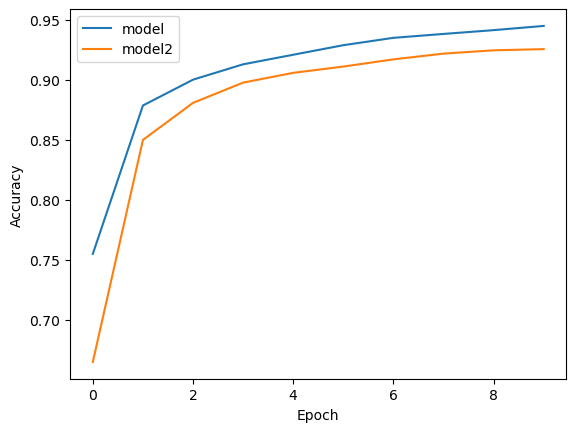

In [24]:
plt.plot(history.history['accuracy'])
plt.plot(history2.history['accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['model', 'model2'], loc='upper left')
plt.show()

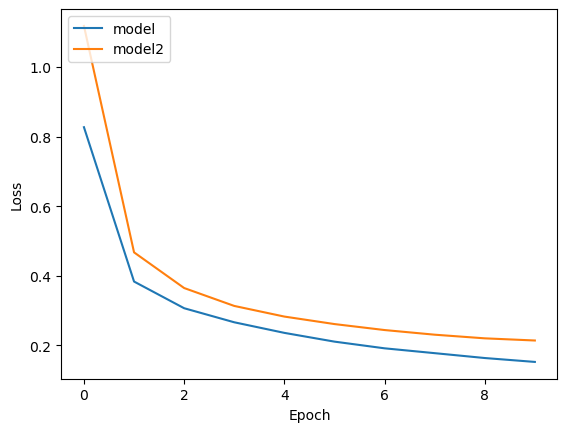

In [25]:
plt.plot(history.history['loss'])
plt.plot(history2.history['loss'])
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['model', 'model2'], loc='upper left')
plt.show()

In [ ]:
model.save_weights('CA2PtA.weights.h5')
